<a href="https://colab.research.google.com/github/serenaycalisir/ml-calisma/blob/main/01_numpy_goruntu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

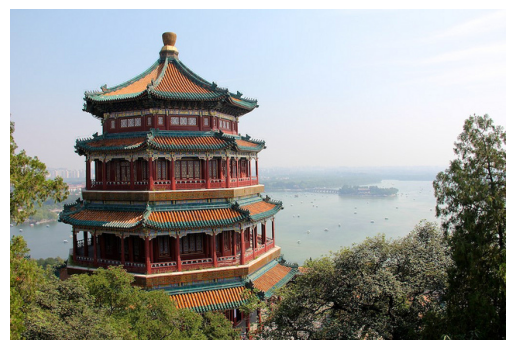

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_sample_image
img = load_sample_image("china.jpg").copy() # Bu örnek görüntü "salt okunur" geliyor.
# Kopyasını alarak üzerinde değişiklik yapabilir hâle getiriyoruz.
plt.imshow(img); plt.axis("off"); plt.show()

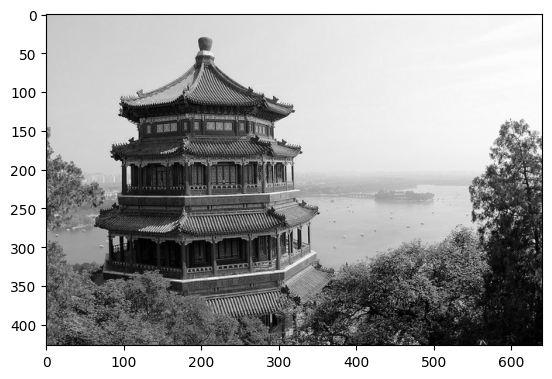

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# 3 kanallı renkli resmi tek kanallı gri tonlamaya dönüştürüyoruz (Luminosity formülü)
gray_img = np.dot(img[...,:3], [0.2989, 0.5870, 0.1140])

# Tek kanallı resimde artık cmap="gray" parametresi çalışacaktır
plt.imshow(gray_img, cmap="gray")
plt.axis("on")
plt.show()

In [14]:
print(type(img))
print(img.shape)
print(img.ndim) # N-dimensional (boyutu)
print(img.size)
print(img.dtype)
print(img.min(), img.max()) #0=tam  siyah 255=tam beyaz
print(img[0,0])

<class 'numpy.ndarray'>
(427, 640, 3)
3
819840
uint8
0 255
[174 201 231]


In [33]:
# Sıfırdan dizi oluşturma
a = np.array([1, 2, 3])
print(a)
z = np.zeros((3, 4)) # 3x4 sıfır (float64)
print(z)
print(z.dtype)
print(z.shape)
o = np.ones((2, 2), dtype = np.uint8)
print(o)
print(o.size)
print(o.dtype)
r = np.arange(0, 10, 2) # [0 2 4 6 8]
print(r)
r2 = np.arange(4, 10, 1)
print(r2)
l = np.linspace(0, 1, 5) # 0'dan 1'e eşit aralıklı 5 sayı
print(l)
rnd = np.random.default_rng(42).integers(0, 256, size=(4, 4), dtype = np.uint8)
#Başındaki 42 (seed değeri) kod her çalıştığında tamamen aynı rastgele sayıların üretilmesini sağlar.
print(rnd)


[1 2 3]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
float64
(3, 4)
[[1 1]
 [1 1]]
4
uint8
[0 2 4 6 8]
[4 5 6 7 8 9]
[0.   0.25 0.5  0.75 1.  ]
[[136  38 217  22]
 [205 251  33 198]
 [193 255 145 167]
 [ 97  86  90 112]]


# **Veri Taşması (Overflow)**

In [30]:
x = np.array([250], dtype=np.uint8)
print(x+10) #255i aşınca başa sarar.

y=x.astype(np.int16) + 10 # önce daha geniş bir türe çevrilir.
print(np.clip(y, 0, 255).astype(np.uint8)) #Sonrasında tekrar eski formata döndürüyoruz.
print(y)


[4]
[255]
[260]


# **Görüntüyü Normalize Etme (Float Dönüşümü)**

Görüntüler üzerinde karmaşık matematiksel işlemler, filtrelemeler veya yapay zeka/derin öğrenme modelleri uygularken tam sayılarla çalışmak (yukarıda bahsettiğimiz taşma sorunları ve bölme işlemlerindeki yuvarlama hataları yüzünden) çok zordur.

Bu yüzden görüntünün piksellerini (0-255 arası)
önce float32 (ondalıklı sayı) formatına çeviririz.

Ardından 255 değerine bölerek tüm pikselleri 0.0 (tam siyah) ile 1.0 (tam beyaz) arasına sıkıştırırız (normalize ederiz). Bu işlem matematiksel hesaplamaların çok daha hassas ve hatasız yapılmasını sağlar.

In [29]:
#Bu yüzden görüntü üzerinde hesap yapmadan önce genelde floata çevrilir.

f = img.astype(np.float32) / 255
print(f.dtype, f.min(), f.max())

float32 0.0 1.0


# Örnekler

1.  100×256 boyutunda, soldan sağa siyahtan beyaza giden bir gri gradyan görüntüsü oluştur ve cmap="gray" ile çiz.

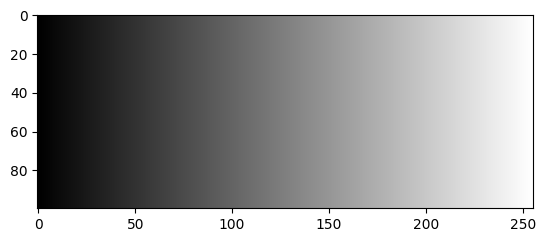

In [31]:
img = np.tile(np.arange(256, dtype=np.uint8), (100, 1)) #(100, 256)
plt.imshow(img, cmap ="gray")
plt.show()

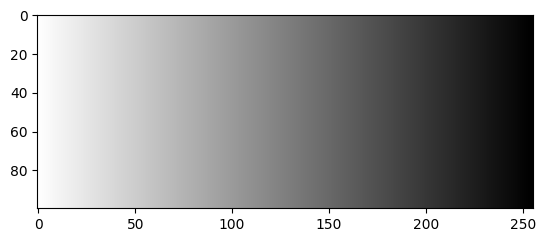

In [34]:
# Beyazdan siyaha (255'ten 0'a) azalan bir dizi oluşturuyoruz
inverted_range = 255 - np.arange(256, dtype=np.uint8)

# Yine 100 satır olacak şekilde alt alta kopyalıyoruz
img2 = np.tile(inverted_range, (100, 1))

plt.imshow(img2, cmap="gray")
plt.show()

In [35]:
dizi = np.arange(34)
print(dizi)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33]


2.   200×200×3 boyutunda, tamamen turuncu (R=255, G=165, B=0) bir görüntü oluştur ve çiz.



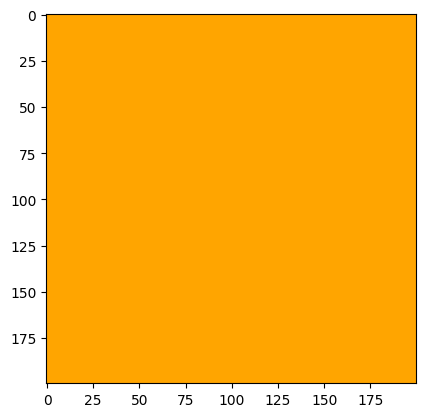

In [39]:
turuncu = np.array([255, 165, 0], dtype=np.uint8)
turuncu_resim = np.tile(turuncu, (200, 200, 1))
plt.imshow(turuncu_resim)
plt.show()

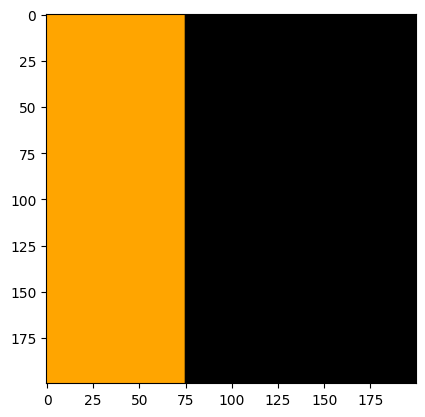

In [41]:
dizi = np.zeros((200, 200, 3), dtype=np.uint8)
dizi[:,:75]=[255, 165, 0]
plt.imshow(dizi)
plt.show()

3.   img'in parlaklığını 80 artır; taşmayı önlemeyi unutma. Orijinalle yan yana çiz.

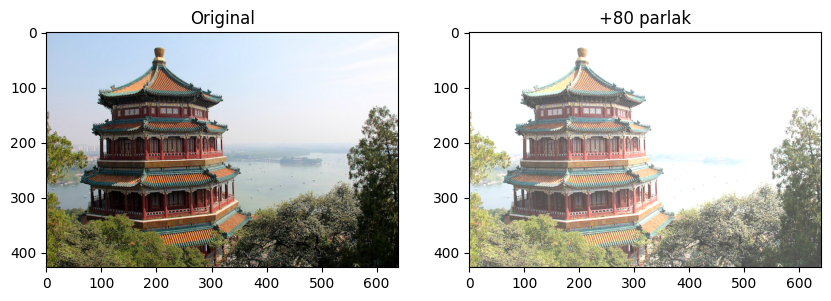

In [ ]:
parlak = np.clip(img.astype(np.int16) + 80, 0, 255).astype(np.uint8)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(img); ax[0].set_title("Original")
ax[1].imshow(parlak); ax[1].set_title("+80 parlak")
plt.show()